In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\HP\Desktop\superstore_sales (1).csv")

In [4]:
print(df.head())

  Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0      1  CA-2017-152156  11-08-2017  11-11-2017    Second Class    CG-12520   
1      2  CA-2017-152156  11-08-2017  11-11-2017    Second Class    CG-12520   
2      3  CA-2017-138688  06-12-2017   6/16/2017    Second Class    DV-13045   
3      4  US-2016-108966  10-11-2016  10/18/2016  Standard Class    SO-20335   
4      5  US-2016-108966  10-11-2016  10/18/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0     42420.0   South  FUR

In [5]:
# Remove missing values
df = df.dropna()

In [6]:
# Convert Order Date into date format
df['Order Date'] = pd.to_datetime(df['Order Date'], format='mixed')

In [7]:
# Convert Sales and Profit into numeric values
df['Sales'] = pd.to_numeric(df['Sales'])

In [8]:
df['Profit'] = pd.to_numeric(df['Profit'])

In [9]:
# Check missing values again
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [10]:
print("Data Cleaning Completed!")

Data Cleaning Completed!


In [11]:
df['Year-Month'] = df['Order Date'].dt.to_period('M')

In [12]:
monthly_sales = df.groupby('Year-Month')['Sales'].sum()

In [13]:
print(monthly_sales)

Year-Month
2015-01     14236.8950
2015-02      4519.8920
2015-03     55691.0090
2015-04     28295.3450
2015-05     23648.2870
2015-06     34595.1276
2015-07     33946.3930
2015-08     27909.4685
2015-09     81777.3508
2015-10     31453.3930
2015-11     78628.7167
2015-12     69545.6205
2016-01     18174.0756
2016-02     11951.4110
2016-03     38726.2520
2016-04     34195.2085
2016-05     30131.6865
2016-06     24797.2920
2016-07     28765.3250
2016-08     36898.3322
2016-09     64595.9180
2016-10     31404.9235
2016-11     70852.4635
2016-12     74919.5212
2017-01     16870.1810
2017-02     22978.8150
2017-03     51715.8750
2017-04     37455.2890
2017-05     56987.7280
2017-06     40344.5340
2017-07     39261.9630
2017-08     31115.3743
2017-09     73410.0249
2017-10     59687.7450
2017-11     79411.9658
2017-12     96999.0430
2018-01     43334.1940
2018-02     20301.1334
2018-03     58872.3528
2018-04     36521.5361
2018-05     44261.1102
2018-06     52981.7257
2018-07     45264.4160


<Axes: xlabel='Year-Month'>

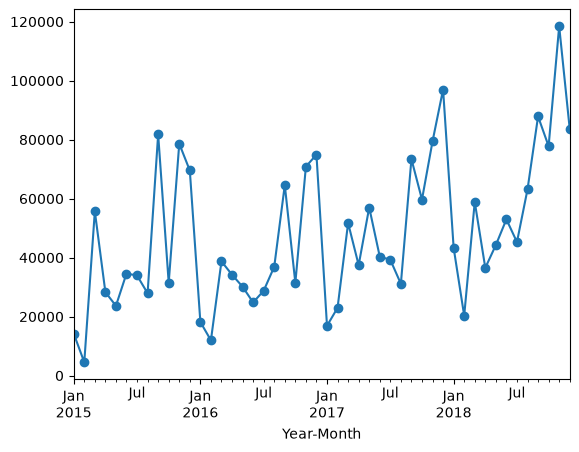

In [14]:
monthly_sales.plot(kind='line', marker='o')

(array([0. , 0.2, 0.4, 0.6, 0.8, 1. ]),
 [Text(0.0, 0, '0.0'),
  Text(0.2, 0, '0.2'),
  Text(0.4, 0, '0.4'),
  Text(0.6000000000000001, 0, '0.6'),
  Text(0.8, 0, '0.8'),
  Text(1.0, 0, '1.0')])

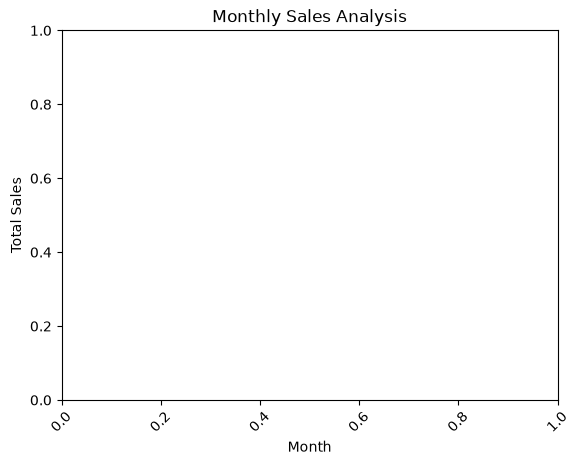

In [15]:
plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

In [16]:
plt.show()

In [17]:
category_sales = df.groupby('Category')['Sales'].sum()

In [18]:
print(category_sales)

Category
Furniture          736879.6953
Office Supplies    716837.5220
Technology         834554.2730
Name: Sales, dtype: float64


<Axes: xlabel='Category'>

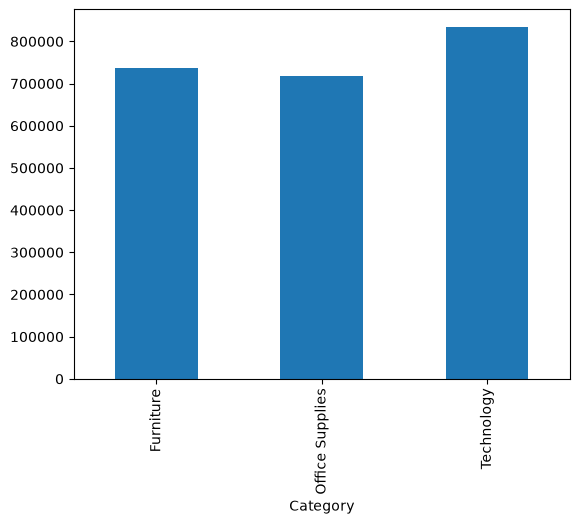

In [19]:
category_sales.plot(kind='bar')

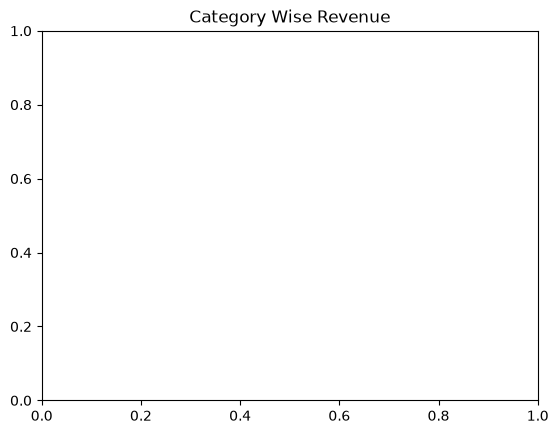

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit',
       'Year-Month'],
      dtype='str')


In [20]:
plt.title("Category Wise Revenue")
plt.show()
print(df.columns)

<Axes: xlabel='Discount', ylabel='Profit'>

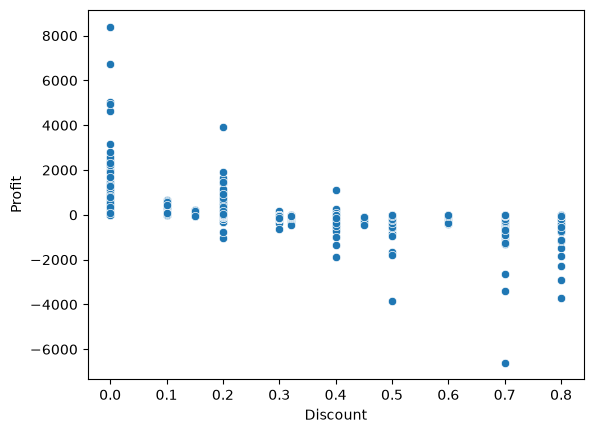

In [21]:
sns.scatterplot(data=df, x='Discount', y='Profit')

Text(0, 0.5, 'Profit')

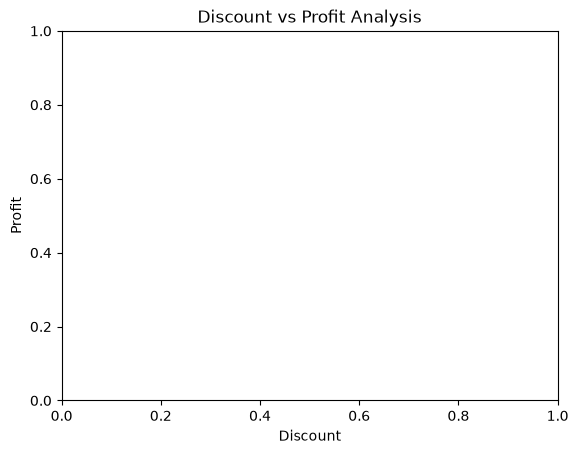

In [22]:
plt.title("Discount vs Profit Analysis")
plt.xlabel("Discount")
plt.ylabel("Profit")

In [23]:
plt.show()

In [24]:
region_sales = df.groupby('Region')['Sales'].sum()

In [25]:
print("Region Wise Sales:")
print(region_sales)

Region Wise Sales:
Region
Central    501239.8908
East       669851.8700
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64


<Axes: xlabel='Region'>

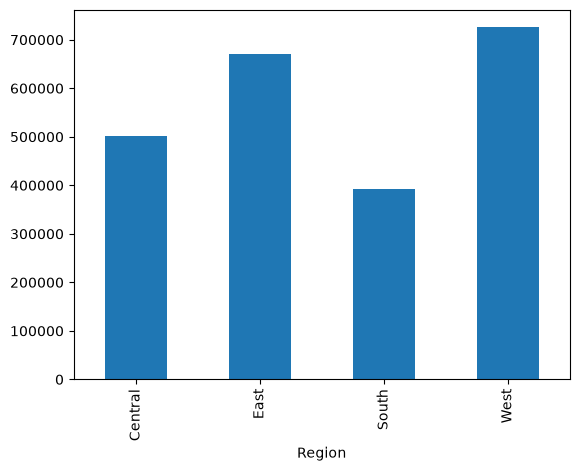

In [26]:
region_sales.plot(kind='bar')

Text(0, 0.5, 'Total Sales')

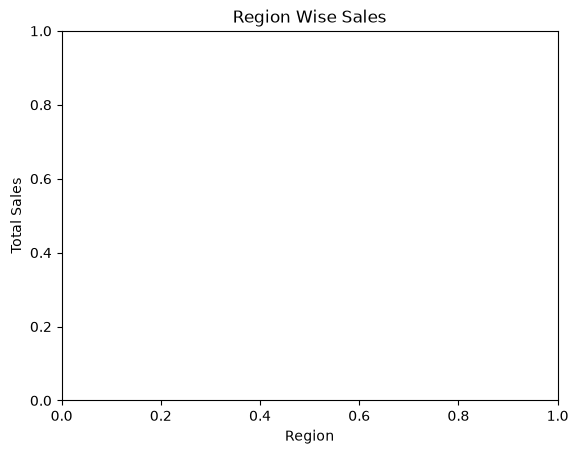

In [27]:
plt.title("Region Wise Sales")
plt.xlabel("Region")
plt.ylabel("Total Sales")

In [28]:
plt.show()

In [29]:
print("\n----- EXECUTIVE SUMMARY -----")


----- EXECUTIVE SUMMARY -----


In [30]:
print("1. Highest Revenue Category:")
print(category_sales.idxmax())

1. Highest Revenue Category:
Technology


In [31]:
print("2. Highest Sales Month:")
print(monthly_sales.idxmax())

2. Highest Sales Month:
2018-11


In [32]:
print("3. Highest Sales Region:")
print(region_sales.idxmax())

3. Highest Sales Region:
West


In [33]:
print("4. Total Sales:")
print(df['Sales'].sum())

4. Total Sales:
2288271.4903


In [34]:
print("5. Total Profit:")
print(df['Profit'].sum())

5. Total Profit:
284152.0434
